# Rail APU Predictive Maintenance: Phase 1 (EDA and Data Preparation)

**Goal:** prepare the data of rail auxiliary power units (APUs) for predicting `Failure`.

**Input files:** `units.csv` (machine information), `gateways.csv` (gateway information, one per machine), `readings.csv` (sensor readings per cycle, with the target `Failure`).

**Steps in this notebook:**
1. Load and inspect the data
2. Harmonise the join key, parse dates, remove duplicates
3. Merge the tables and handle missing and abnormal values
4. Check outliers
5. Test one hypothesis (`hours_service` vs `Failure`), including its statistical power

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.power import TTestIndPower
from scipy.stats import mannwhitneyu, spearmanr

gateways = pd.read_csv("gateways.csv", sep = ";")
readings = pd.read_csv("readings.csv", sep = "\t")
units = pd.read_csv("units.csv")

## 1. Load and inspect the data

Each table is shown with `head()` and `info()` to check column names, types and missing values.

In [2]:
gateways.head()

,Vendor,firmwareVersion,unitId,lon,macAddress,dbm_signal,lat,gatewayId,depotId,ipv4,Technician
0,Barbosa,v1.2.5,93.0,-7.46559,3a:46:15:63:04:a8,-86.7,38.96095,GW-00000,114,153.4.159.186,Brian Jenkins
1,Maldonado-Meadows,v3.4.1,472.0,-7.56956,79:de:94:cf:54:f8,-80.4,41.55315,GW-00001,19,252.36.179.106,Beth Haley
2,Kobelt Dörr e.V.,v1.2.5,1631.0,-8.65907,9f:f5:09:dc:c2:31,-75.2,39.99385,GW-00002,10,167.59.69.69,Reginald Ramirez
3,Monteiro S/A,v3.4.1,1963.0,-6.45996,26:21:ce:f2:14:c5,-62.7,40.97095,GW-00003,18,4.188.18.104,Burkard Zänker
4,Nogueira S/A,v3.4.1,884.0,-8.12230,aa:b9:61:ab:f0:4c,-97.0,40.06582,GW-00004,16,192.190.11.18,Annett Gute


In [3]:
gateways.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Vendor           16000 non-null  str    
 1   firmwareVersion  16000 non-null  str    
 2   unitId           2000 non-null   float64
 3   lon              16000 non-null  float64
 4   macAddress       16000 non-null  str    
 5   dbm_signal       16000 non-null  float64
 6   lat              16000 non-null  float64
 7   gatewayId        16000 non-null  str    
 8   depotId          16000 non-null  int64  
 9   ipv4             16000 non-null  str    
 10  Technician       16000 non-null  str    
dtypes: float64(4), int64(1), str(6)
memory usage: 2.4 MB


In [4]:
readings.head()

,unitId,cycleTs,current_motor,dpFilter,temperature_oil,pressure_reservoir,workingPressure,oilPressure,rmsVibration,Flowmeter,humidityIntake,noise_ambient,bearing_temp,dewpointDischarge,current_aux,Failure
0,U01329,25 May 2023,6.71929,21.87766,64.77747,8.11455,7.91551,3.02071,4.61349,30.10084,65.36553,70.29946,57.69784,8.88160,3.06809,0
1,U01258,06 Sep 2023,3.13811,19.52656,34.57954,8.82466,8.68238,3.29420,1.83718,37.34402,37.71682,77.50199,65.55038,9.58167,1.25770,0
2,U01227,2023/11/03,5.82233,30.68542,61.10665,9.47460,9.42807,4.26590,2.37102,26.46135,40.17996,88.51935,71.53235,9.92301,2.17895,0
3,U01286,2023-03-16,6.02495,17.42087,39.99443,8.61758,8.53750,3.53579,1.79428,29.34227,67.91587,76.30319,69.83793,3.62698,3.27188,0
4,U01142,"02/23/2023, 22:22:00",4.02728,18.43864,64.33452,8.63675,8.74389,3.59906,3.09071,27.19217,39.59432,71.08868,59.30049,7.94037,2.69904,0


In [5]:
readings.info()

<class 'pandas.DataFrame'>
RangeIndex: 16038 entries, 0 to 16037
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   unitId              16038 non-null  str    
 1   cycleTs             16038 non-null  str    
 2   current_motor       16038 non-null  float64
 3   dpFilter            15429 non-null  float64
 4   temperature_oil     16038 non-null  float64
 5   pressure_reservoir  16038 non-null  float64
 6   workingPressure     16038 non-null  float64
 7   oilPressure         16038 non-null  float64
 8   rmsVibration        15361 non-null  float64
 9   Flowmeter           16038 non-null  float64
 10  humidityIntake      15211 non-null  float64
 11  noise_ambient       16038 non-null  float64
 12  bearing_temp        16038 non-null  float64
 13  dewpointDischarge   16038 non-null  float64
 14  current_aux         16038 non-null  float64
 15  Failure             16038 non-null  int64  
dtypes: float64(13),

In [6]:
units.head()

,year_commission,overhaul_last,codeModel,unitId,regionInstall,owner_operator,serial_number,depotId,duty_class,line_code,hours_service,code_fleet,Manufacturer
0,2022,2018-05-21,XC-7,1,Schrobenhausen,Jones-Davies,YK-9092-54795,106,3,L1,9388.9,FD,Kabus Rogner GmbH
1,2020,07 Oct 2020,APU-15,2,Ahaus,Carvalho Leite S/A,MK-5868-13759,13,L,L6,14764.5,FE,Köhler OHG mbH
2,2022,2017-07-05,APU-15,3,São Salvador de Lordelo,Murray Group,PI-0711-68546,62,light,L1,8476.6,FB,Jähn AG
3,2022,2021-11-16,APU-15,4,Amora,Austermühle,JJ-6819-11879,3,3,L3,8316.2,FB,Sá Leite Lda.
4,2022,13 Aug 2024,APU-20,5,Douglasside,Murray Group,HJ-1947-75387,115,2,L3,8810.8,FB,Hamilton-Smith


In [7]:
units.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   year_commission  2000 non-null   int64  
 1   overhaul_last    2000 non-null   str    
 2   codeModel        2000 non-null   str    
 3   unitId           2000 non-null   int64  
 4   regionInstall    2000 non-null   str    
 5   owner_operator   2000 non-null   str    
 6   serial_number    2000 non-null   str    
 7   depotId          2000 non-null   int64  
 8   duty_class       2000 non-null   str    
 9   line_code        2000 non-null   str    
 10  hours_service    1900 non-null   float64
 11  code_fleet       2000 non-null   str    
 12  Manufacturer     2000 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 345.4 KB


### 1.2 Harmonise the join key `unitId`

The three tables describe the same machines, but `unitId` is stored in different formats. In `readings` it is a string such as `U01329`, while in the other tables it is a plain number. Before merging, every table gets the same numeric key (`int64`).

The cell below extracts the digits, converts them to numbers and casts the result to `int64`. Values without any digits are dropped by `dropna()`.

In [8]:
units_num = pd.to_numeric(
    units['unitId'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce'
).dropna().astype('int64')

readings_num = pd.to_numeric(
    readings['unitId'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce'
).dropna().astype('int64')

gateways_num = pd.to_numeric(
    gateways['unitId'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce'
).dropna().astype('int64')

for name, s in [('units', units_num), ('readings', readings_num), ('gateways', gateways_num)]:
    print(f"{name}: count={len(s)}, unique={s.nunique()}, min={s.min()}, max={s.max()}")

print("units ∩ readings:", len(set(units_num) & set(readings_num)))
print("gateways ∩ readings:", len(set(gateways_num) & set(readings_num)))
print("units ∩ gateways:", len(set(units_num) & set(gateways_num)))

units['unitId'] = units_num
readings['unitId'] = readings_num
gateways['unitId'] = gateways_num

units: count=2000, unique=2000, min=1, max=2000
readings: count=16038, unique=2125, min=1, max=90499
gateways: count=2000, unique=2000, min=1, max=2000
units ∩ readings: 2000
gateways ∩ readings: 2000
units ∩ gateways: 2000


After the conversion, every `unitId` in `units` and `gateways` is also in the other two tables. `readings` has 125 additional IDs that do not exist in `units`. These are kept for now and are handled by the merge and the missing-value step.

**Dates:** the date columns use several formats in the same column. They are parsed with `format='mixed'` and `dayfirst=True`. Ambiguous slash dates (for example `02/03/2023`) should be checked, because `dayfirst` decides how they are read.

In [9]:
readings['cycleTs'] = pd.to_datetime(readings.cycleTs, format='mixed', dayfirst=True)
units['overhaul_last'] = pd.to_datetime(units.overhaul_last, format='mixed', dayfirst=True)

In [10]:
readings.head()

,unitId,cycleTs,current_motor,dpFilter,temperature_oil,pressure_reservoir,workingPressure,oilPressure,rmsVibration,Flowmeter,humidityIntake,noise_ambient,bearing_temp,dewpointDischarge,current_aux,Failure
0,1329,2023-05-25 00:00:00,6.71929,21.87766,64.77747,8.11455,7.91551,3.02071,4.61349,30.10084,65.36553,70.29946,57.69784,8.88160,3.06809,0
1,1258,2023-09-06 00:00:00,3.13811,19.52656,34.57954,8.82466,8.68238,3.29420,1.83718,37.34402,37.71682,77.50199,65.55038,9.58167,1.25770,0
2,1227,2023-03-11 00:00:00,5.82233,30.68542,61.10665,9.47460,9.42807,4.26590,2.37102,26.46135,40.17996,88.51935,71.53235,9.92301,2.17895,0
3,1286,2023-03-16 00:00:00,6.02495,17.42087,39.99443,8.61758,8.53750,3.53579,1.79428,29.34227,67.91587,76.30319,69.83793,3.62698,3.27188,0
4,1142,2023-02-23 22:22:00,4.02728,18.43864,64.33452,8.63675,8.74389,3.59906,3.09071,27.19217,39.59432,71.08868,59.30049,7.94037,2.69904,0


In [11]:
units.head()

,year_commission,overhaul_last,codeModel,unitId,regionInstall,owner_operator,serial_number,depotId,duty_class,line_code,hours_service,code_fleet,Manufacturer
0,2022,2018-05-21,XC-7,1,Schrobenhausen,Jones-Davies,YK-9092-54795,106,3,L1,9388.9,FD,Kabus Rogner GmbH
1,2020,2020-10-07,APU-15,2,Ahaus,Carvalho Leite S/A,MK-5868-13759,13,L,L6,14764.5,FE,Köhler OHG mbH
2,2022,2017-05-07,APU-15,3,São Salvador de Lordelo,Murray Group,PI-0711-68546,62,light,L1,8476.6,FB,Jähn AG
3,2022,2021-11-16,APU-15,4,Amora,Austermühle,JJ-6819-11879,3,3,L3,8316.2,FB,Sá Leite Lda.
4,2022,2024-08-13,APU-20,5,Douglasside,Murray Group,HJ-1947-75387,115,2,L3,8810.8,FB,Hamilton-Smith


## 2. Duplicates and merge

### 1.3 Duplicates

The dates are now parsed. Next, I check whether any table contains fully duplicated rows.

Only `readings` has duplicates (237 rows). `gateways` and `units` have none.

In [12]:
gate_dup = gateways.duplicated()
read_dup = readings.duplicated()
unit_dup = units.duplicated()
gate_dup[gate_dup == True]

Series([], dtype: bool)

In [13]:
read_dup[read_dup == True]

15801    True
15802    True
15803    True
15804    True
15805    True
         ... 
16033    True
16034    True
16035    True
16036    True
16037    True
Length: 237, dtype: bool

In [14]:
unit_dup[unit_dup == True]

Series([], dtype: bool)

Duplicates are removed from `readings` only. `drop_duplicates()` keeps the first occurrence of each identical row.

In [15]:
readings = readings.drop_duplicates()
readings

,unitId,cycleTs,current_motor,dpFilter,temperature_oil,pressure_reservoir,workingPressure,oilPressure,rmsVibration,Flowmeter,humidityIntake,noise_ambient,bearing_temp,dewpointDischarge,current_aux,Failure
0,1329,2023-05-25 00:00:00,6.71929,21.87766,64.77747,8.11455,7.91551,3.02071,4.61349,30.10084,65.36553,70.29946,57.69784,8.88160,3.06809,0
1,1258,2023-09-06 00:00:00,3.13811,19.52656,34.57954,8.82466,8.68238,3.29420,1.83718,37.34402,37.71682,77.50199,65.55038,9.58167,1.25770,0
2,1227,2023-03-11 00:00:00,5.82233,30.68542,61.10665,9.47460,9.42807,4.26590,2.37102,26.46135,40.17996,88.51935,71.53235,9.92301,2.17895,0
3,1286,2023-03-16 00:00:00,6.02495,17.42087,39.99443,8.61758,8.53750,3.53579,1.79428,29.34227,67.91587,76.30319,69.83793,3.62698,3.27188,0
4,1142,2023-02-23 22:22:00,4.02728,18.43864,64.33452,8.63675,8.74389,3.59906,3.09071,27.19217,39.59432,71.08868,59.30049,7.94037,2.69904,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,4,2023-09-01 00:00:00,7.22435,34.32168,74.97317,9.26551,9.44128,4.73111,3.21881,30.55995,59.67272,72.67528,59.17655,9.98580,3.16353,0
15797,942,2023-12-18 00:00:00,7.67824,11.91848,67.41676,8.39882,8.31226,3.50324,2.61739,25.51800,19.59034,77.15048,72.68885,10.85358,2.49142,0
15798,981,2023-04-01 14:40:00,4.22188,18.41790,64.81536,8.70319,8.60772,3.45481,3.84060,27.78392,34.56774,85.18848,45.18388,12.68663,3.29164,0
15799,1383,2023-04-28 00:00:00,4.34741,14.15081,36.73282,8.91858,8.95513,3.94528,2.36587,27.52719,76.23579,75.06338,75.12766,5.55397,3.37194,1


### 1.4 Merge the tables

The tables are combined on `unitId`:

1. `units` and `gateways` are joined with an inner join, so only machines present in both are kept.
2. The readings are attached with a right join, so every reading is kept.

Readings whose `unitId` has no matching machine get missing values in the unit columns. These rows are removed in the missing-value step.

In [16]:
data = units.merge(gateways,on='unitId', how='inner')
data = data.merge(readings, on='unitId', how='right')
data

,year_commission,overhaul_last,codeModel,unitId,regionInstall,owner_operator,serial_number,depotId_x,duty_class,line_code,...,workingPressure,oilPressure,rmsVibration,Flowmeter,humidityIntake,noise_ambient,bearing_temp,dewpointDischarge,current_aux,Failure
0,2023.0,2019-04-05,APU-20,1329,Lübeck,Duncan-Lynch,LJ-7674-12279,99.0,H,L4,...,7.91551,3.02071,4.61349,30.10084,65.36553,70.29946,57.69784,8.88160,3.06809,0
1,2017.0,2019-07-05,APU-15,1258,South Lesliemouth,Sá Leite Lda.,JX-7532-71445,32.0,1,L4,...,8.68238,3.29420,1.83718,37.34402,37.71682,77.50199,65.55038,9.58167,1.25770,0
2,2021.0,2017-02-22,XC-7,1227,Walterton,Mülichen AG,VZ-4260-35538,58.0,N,L5,...,9.42807,4.26590,2.37102,26.46135,40.17996,88.51935,71.53235,9.92301,2.17895,0
3,2023.0,2022-11-13,XC-7,1286,São Salvador de Lordelo,Stumpf GmbH,JB-4632-99222,17.0,3,L3,...,8.53750,3.53579,1.79428,29.34227,67.91587,76.30319,69.83793,3.62698,3.27188,0
4,2023.0,2021-06-23,APU-20,1142,Setúbal,Jones-Davies,EI-0981-89563,54.0,med,L4,...,8.74389,3.59906,3.09071,27.19217,39.59432,71.08868,59.30049,7.94037,2.69904,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,2022.0,2021-11-16,APU-15,4,Amora,Austermühle,JJ-6819-11879,3.0,3,L3,...,9.44128,4.73111,3.21881,30.55995,59.67272,72.67528,59.17655,9.98580,3.16353,0
15797,2023.0,2021-08-10,XC-7,942,East Crystal,Austin and Sons,QM-2002-68469,85.0,heavy,L1,...,8.31226,3.50324,2.61739,25.51800,19.59034,77.15048,72.68885,10.85358,2.49142,0
15798,2021.0,2022-12-06,APU-15,981,North Jacobton,Ortmann GmbH & Co. KGaA,GQ-5834-48181,24.0,1,L6,...,8.60772,3.45481,3.84060,27.78392,34.56774,85.18848,45.18388,12.68663,3.29164,0
15799,2020.0,2019-06-07,APU-12,1383,Lübeck,Rogge Wiek AG,UV-6045-40373,90.0,2,L5,...,8.95513,3.94528,2.36587,27.52719,76.23579,75.06338,75.12766,5.55397,3.37194,1


In [17]:
data_dup = data.duplicated()
data_dup[data_dup == True]

Series([], dtype: bool)

After the merge, the table has no duplicate rows. Next, I check the share of missing values in each column.

In [18]:
round((data.isnull().sum() / data.shape[0]) * 100, 2)

year_commission       0.91
overhaul_last         0.91
codeModel             0.91
unitId                0.00
regionInstall         0.91
owner_operator        0.91
serial_number         0.91
depotId_x             0.91
duty_class            0.91
line_code             0.91
hours_service         5.79
code_fleet            0.91
Manufacturer          0.91
Vendor                0.91
firmwareVersion       0.91
lon                   0.91
macAddress            0.91
dbm_signal            0.91
lat                   0.91
gatewayId             0.91
depotId_y             0.91
ipv4                  0.91
Technician            0.91
cycleTs               0.00
current_motor         0.00
dpFilter              3.77
temperature_oil       0.00
pressure_reservoir    0.00
workingPressure       0.00
oilPressure           0.00
rmsVibration          4.21
Flowmeter             0.00
humidityIntake        5.14
noise_ambient         0.00
bearing_temp          0.00
dewpointDischarge     0.00
current_aux           0.00
F

### 1.5 Missing values

About 0.91% of the values are missing in 21 columns. Next I check whether these missing values come from the same rows.

In [19]:
no_id = data['codeModel'].isna()

cols_091 = ['year_commission', 'overhaul_last', 'codeModel', 'regionInstall',
            'owner_operator', 'serial_number', 'depotId_x', 'duty_class',
            'line_code', 'code_fleet', 'Manufacturer', 'Vendor', 'firmwareVersion',
            'lon', 'macAddress', 'dbm_signal', 'lat', 'gatewayId', 'depotId_y',
            'ipv4', 'Technician']

print("without id:", no_id.sum())
print("rows with Nan in this columns:", data[cols_091].isna().any(axis=1).sum())
print("The same one", (no_id == data[cols_091].isna().any(axis=1)).all())

without id: 144
rows with Nan in this columns: 144
The same one True


All the 0.91% missing values come from the same 144 rows. These are readings whose `unitId` has no matching record in `units` or `gateways` (orphan records). Their machine information cannot be filled in, so they are dropped.

In [20]:
data = data.dropna(subset=['codeModel']).reset_index(drop=True)

In [21]:
round((data.isnull().sum() / data.shape[0]) * 100, 2)

year_commission       0.00
overhaul_last         0.00
codeModel             0.00
unitId                0.00
regionInstall         0.00
owner_operator        0.00
serial_number         0.00
depotId_x             0.00
duty_class            0.00
line_code             0.00
hours_service         4.92
code_fleet            0.00
Manufacturer          0.00
Vendor                0.00
firmwareVersion       0.00
lon                   0.00
macAddress            0.00
dbm_signal            0.00
lat                   0.00
gatewayId             0.00
depotId_y             0.00
ipv4                  0.00
Technician            0.00
cycleTs               0.00
current_motor         0.00
dpFilter              3.76
temperature_oil       0.00
pressure_reservoir    0.00
workingPressure       0.00
oilPressure           0.00
rmsVibration          4.19
Flowmeter             0.00
humidityIntake        5.12
noise_ambient         0.00
bearing_temp          0.00
dewpointDischarge     0.00
current_aux           0.00
F

## 3. Missing values

After dropping these rows, the remaining missing values are in `hours_service` (about 4.9%), `dpFilter`, `rmsVibration` and `humidityIntake` (about 4% each).

### 1.6 Missing `hours_service`

Before filling `hours_service`, I check whether a missing value is related to failures. The indicator `service_missing` marks missing values with 1.

In [22]:
data['service_missing'] = data['hours_service'].isna().astype(int)
print(data.groupby('service_missing')['Failure'].agg(['mean', 'size']))

                     mean   size
service_missing                 
0                0.117291  14886
1                0.124514    771


The failure rate is about 12.5% when `hours_service` is missing and about 11.7% when it is present, so the difference is small.

Missing values are filled with 0, which means "no recorded service hours". This is an assumption, not a verified fact. The `service_missing` indicator is created before filling, so the information is not lost. It is dropped again in section 1.8.

In [23]:
data['hours_service'] = data['hours_service'].fillna(0)

### 1.7 Sensor columns

`dpFilter`, `rmsVibration` and `humidityIntake` are time series for each machine. Missing values are filled by linear interpolation within each machine, ordered by `cycleTs`. `limit_direction='both'` also fills gaps at the start or end of a machine's series.

This is done on the whole dataset. In Phase 2 the same step should be fitted on the training data only, to avoid leakage into the test set.

In [24]:
sensor_cols = ['dpFilter', 'rmsVibration', 'humidityIntake']

data = data.sort_values(['unitId', 'cycleTs'])
data[sensor_cols] = (
    data.groupby('unitId')[sensor_cols]
        .transform(lambda s: s.interpolate(limit_direction='both'))
)

In [25]:
round((data.isnull().sum() / data.shape[0]) * 100, 2)

year_commission       0.0
overhaul_last         0.0
codeModel             0.0
unitId                0.0
regionInstall         0.0
owner_operator        0.0
serial_number         0.0
depotId_x             0.0
duty_class            0.0
line_code             0.0
hours_service         0.0
code_fleet            0.0
Manufacturer          0.0
Vendor                0.0
firmwareVersion       0.0
lon                   0.0
macAddress            0.0
dbm_signal            0.0
lat                   0.0
gatewayId             0.0
depotId_y             0.0
ipv4                  0.0
Technician            0.0
cycleTs               0.0
current_motor         0.0
dpFilter              0.0
temperature_oil       0.0
pressure_reservoir    0.0
workingPressure       0.0
oilPressure           0.0
rmsVibration          0.0
Flowmeter             0.0
humidityIntake        0.0
noise_ambient         0.0
bearing_temp          0.0
dewpointDischarge     0.0
current_aux           0.0
Failure               0.0
service_miss

## 4. Integrity checks and abnormal values

### 1.8 Duplicated columns from the merge

Both `units` and `gateways` contain `depotId`, so the merge creates `depotId_x` and `depotId_y`. The check below finds no rows where they differ. One copy is dropped, `depotId_x` is renamed to `depotId`, and the `service_missing` indicator is removed.

In [26]:
depo = data['depotId_x'] == data['depotId_y']
depo[depo == False]

Series([], dtype: bool)

In [27]:
data = data.drop('depotId_y', axis=1)
data.rename(columns={'depotId_x': 'depotId'}, inplace=True)

### 1.9 Abnormal values

For each numeric column I look at the minimum, maximum, mean, standard deviation, and the number of negative and zero values. The goal is to find impossible or suspicious values.

In [28]:
num_cols = data.select_dtypes(include='number').columns.drop(['Failure', 'unitId'], errors='ignore')
desc = data[num_cols].describe().T
desc['neg_count'] = (data[num_cols] < 0).sum()
desc['zero_count'] = (data[num_cols] == 0).sum()
print(desc[['min', 'max', 'mean', 'std', 'neg_count', 'zero_count']].round(2))

                        min       max      mean      std  neg_count  \
year_commission     2012.00   2024.00   2020.47     2.50          0   
depotId                0.00    119.00     55.25    34.40          0   
hours_service          0.00  45000.00  13514.97  9141.45          0   
lon                   -9.30     -6.20     -7.78     0.89      15657   
dbm_signal          -105.60    -40.00    -70.12    10.24      15657   
lat                   38.60     41.70     40.15     0.89          0   
current_motor          0.10     99.00      5.27     3.50          0   
dpFilter               7.08    120.00     24.03    11.27          0   
temperature_oil     -999.00     95.00     51.43    61.24         51   
pressure_reservoir     6.50     10.50      8.71     0.60          0   
workingPressure        6.36     10.50      8.71     0.62          0   
oilPressure            1.50      5.91      3.71     0.57          0   
rmsVibration           0.50     14.00      3.09     1.62          0   
Flowme

The minimum of `temperature_oil` is -999. This is a sentinel code, not a real temperature. The code replaces it with NaN. The NaN values are then interpolated together with `current_aux` (see below).

Zeros in `depotId` and `current_aux` are checked in the next cells.

In [29]:
data['temperature_oil'] = data['temperature_oil'].replace(-999, np.nan)

In [30]:
data.isnull().sum()

year_commission        0
overhaul_last          0
codeModel              0
unitId                 0
regionInstall          0
owner_operator         0
serial_number          0
depotId                0
duty_class             0
line_code              0
hours_service          0
code_fleet             0
Manufacturer           0
Vendor                 0
firmwareVersion        0
lon                    0
macAddress             0
dbm_signal             0
lat                    0
gatewayId              0
ipv4                   0
Technician             0
cycleTs                0
current_motor          0
dpFilter               0
temperature_oil       51
pressure_reservoir     0
workingPressure        0
oilPressure            0
rmsVibration           0
Flowmeter              0
humidityIntake         0
noise_ambient          0
bearing_temp           0
dewpointDischarge      0
current_aux            0
Failure                0
service_missing        0
dtype: int64

In [31]:
data.loc[data['depotId']==0, 'unitId'].nunique()

19

In [32]:
per_unit = data.groupby('unitId')['depotId'].nunique()
print("машин з декількома depotId:", (per_unit > 1).sum())
print("значення depotId у машин з нулем:",
      data.loc[data['depotId']==0].groupby('unitId')['depotId'].first().value_counts().head())

машин з декількома depotId: 0
значення depotId у машин з нулем: depotId
0.0    19
Name: count, dtype: int64


**`depotId = 0`:** 19 machines have depot 0. Each of them has only this one value across all its rows, and no machine has more than one depot. Zero therefore looks like a valid placeholder code, not a data error, so these rows are kept.

In [33]:
zero_aux = data[data['current_aux'] == 0]
print(zero_aux.groupby('unitId').size().describe())

count    27.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
dtype: float64


In [34]:
zero_idx = data.index[data['current_aux'] == 0]
for i in zero_idx[:3]:
    u = data.loc[i, 'unitId']
    print(data.loc[data['unitId'] == u, ['cycleTs', 'current_aux']].assign(
        is_zero=lambda d: d['current_aux'] == 0).to_string(), '\n')

                  cycleTs  current_aux  is_zero
9061  2023-01-12 03:53:00      2.31553    False
12613 2023-02-16 19:05:00      3.40447    False
5990  2023-03-18 00:00:00      3.65319    False
11997 2023-03-21 00:00:00      2.47741    False
3072  2023-03-22 08:48:00      1.25337    False
14488 2023-04-24 00:00:00      3.22512    False
13034 2023-07-19 00:00:00      3.15193    False
13869 2023-07-19 00:00:00      2.01208    False
5272  2023-10-28 00:12:00      2.79948    False
4888  2023-11-24 00:00:00      4.14399    False
14826 2023-12-20 00:00:00      0.00000     True
10444 2023-12-22 00:00:00      2.88057    False
13365 2023-12-27 00:00:00      2.48280    False 

                  cycleTs  current_aux  is_zero
2917  2023-01-18 00:00:00      2.64247    False
7269  2023-02-09 00:00:00      2.06998    False
10088 2023-03-27 00:00:00      2.03006    False
14616 2023-07-02 00:00:00      2.46760    False
7600  2023-07-15 00:00:00      2.28057    False
13010 2023-08-04 00:00:00      0.00000

In [35]:
data['current_aux'] = data['current_aux'].replace(0.0, np.nan)

**`current_aux = 0`:** there are 27 zero values, and each affected machine has exactly one zero. The zeros look like single-reading sensor dropouts, because the values before and after are close to normal. The zeros are set to NaN and interpolated, in the same way as `temperature_oil`.

In [36]:
abnormal_cols = ['current_aux', 'temperature_oil']

data = data.sort_values(['unitId', 'cycleTs'])
data[abnormal_cols] = (
    data.groupby('unitId')[abnormal_cols]
        .transform(lambda s: s.interpolate(limit_direction='both'))
)

## 5. Outliers

Numeric columns are checked with the IQR rule: a value is flagged if it lies outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.

Flagged values are not deleted automatically. Failures are often the extreme values, so removing them would remove the signal we want to model. Instead, the flagged rows are counted per class, and an alternative treatment (clipping to the 5th and 95th percentiles) is shown for comparison.

In [37]:
exclude = ['unitId', 'depotId', 'Failure', 'service_missing', 'year_commission',
           'lon', 'lat', 'dbm_signal', 'hours_service']
num_cols = [c for c in data.select_dtypes(include='number').columns if c not in exclude]
print(num_cols)

['current_motor', 'dpFilter', 'temperature_oil', 'pressure_reservoir', 'workingPressure', 'oilPressure', 'rmsVibration', 'Flowmeter', 'humidityIntake', 'noise_ambient', 'bearing_temp', 'dewpointDischarge', 'current_aux']


In [38]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

iqr_mask = pd.Series(False, index=data.index)
iqr_counts = {}
for col in num_cols:
    lo, hi = iqr_bounds(data[col])
    out = (data[col] < lo) | (data[col] > hi)
    iqr_counts[col] = out.sum()
    iqr_mask |= out

print(pd.Series(iqr_counts, name="IQR outliers").to_string())
print(f"\nRows with at least one IQR outlier: {iqr_mask.sum()} of {len(data)}")
print(data.loc[iqr_mask, "Failure"].value_counts())

current_motor          16
dpFilter              700
temperature_oil       109
pressure_reservoir    102
workingPressure       101
oilPressure           103
rmsVibration          568
Flowmeter              97
humidityIntake          0
noise_ambient          94
bearing_temp          122
dewpointDischarge     120
current_aux            99

Rows with at least one IQR outlier: 2007 of 15657
Failure
0    1661
1     346
Name: count, dtype: int64


In [39]:
data_clip = data.copy()
for col in num_cols:
    lo, hi = data[col].quantile([0.05, 0.95])
    data_clip[col] = data[col].clip(lower=lo, upper=hi)

clipped = {c: (data[c] != data_clip[c]).sum() for c in num_cols}
print(pd.Series(clipped, name="values clipped").to_string())

current_motor         1566
dpFilter              1566
temperature_oil       1566
pressure_reservoir    1566
workingPressure       1566
oilPressure           1566
rmsVibration          1566
Flowmeter             1566
humidityIntake        1566
noise_ambient         1566
bearing_temp          1566
dewpointDischarge     1566
current_aux           1566


### 5.1 Technique 1: removal of IQR outliers

Rows flagged by the IQR rule in any numeric column are removed. This shrinks the data and also removes failure rows that happen to be extreme.

In [40]:
data_removed = data.loc[~iqr_mask].copy()

print("Rows before:", len(data), "| after IQR removal:", len(data_removed))
print("Failures before:", int(data["Failure"].sum()), "| after:", int(data_removed["Failure"].sum()))
print("Failure rate before:", round(data["Failure"].mean(), 4), "| after:", round(data_removed["Failure"].mean(), 4))

Rows before: 15657 | after IQR removal: 13650
Failures before: 1842 | after: 1496
Failure rate before: 0.1176 | after: 0.1096


### 5.2 Technique 2: capping at the 5th and 95th percentiles

Each numeric column is limited to its own 5th and 95th percentile. Every row is kept, but extreme values are moved to the limit.

In [41]:
data_capped = data.copy()
for col in num_cols:
    lo, hi = data[col].quantile([0.05, 0.95])
    data_capped[col] = data[col].clip(lower=lo, upper=hi)

print("Rows before:", len(data), "| after capping:", len(data_capped))
print("Failures before:", int(data["Failure"].sum()), "| after capping:", int(data_capped["Failure"].sum()))

Rows before: 15657 | after capping: 15657
Failures before: 1842 | after capping: 1842


### 5.3 Comparison of the two techniques

To see the effect, the same check is run on all three versions of the data: the mean and spread of `Flowmeter`, and the AUC of `Flowmeter` for separating failure from non-failure rows (one-sided Mann-Whitney U test).

`Flowmeter` is used here because it is a sensor column that was treated by both techniques, and it is the example variable in the assignment.

In [42]:
def compare(df, label):
    f1 = df.loc[df["Failure"] == 1, "Flowmeter"]
    f0 = df.loc[df["Failure"] == 0, "Flowmeter"]
    u, p = mannwhitneyu(f1, f0, alternative="greater")
    print(f"{label:<14} n={len(df):>6}  failures={int(df['Failure'].sum()):>4}  "
          f"mean={df['Flowmeter'].mean():.2f}  sd={df['Flowmeter'].std():.2f}  "
          f"AUC={u / (len(f1) * len(f0)):.3f}  p={p:.2e}")

compare(data, "original")
compare(data_removed, "IQR removed")
compare(data_capped, "capped 5-95%")

original       n= 15657  failures=1842  mean=28.02  sd=4.00  AUC=0.489  p=9.29e-01
IQR removed    n= 13650  failures=1496  mean=27.99  sd=3.90  AUC=0.489  p=9.10e-01
capped 5-95%   n= 15657  failures=1842  mean=28.02  sd=3.66  AUC=0.490  p=9.28e-01


### 5.4 Decision

**Removal is not used.** It deletes about 2,000 rows, and among them are the failure rows that the IQR rule flags. A model trained on the remaining data would see fewer failures and fewer extreme failure cases, so it would look better on paper than it would be on new machines. The comparison above shows how many failure rows are lost.

**Capping is used.** It keeps every row, including all failures, and only limits the most extreme values. Its drawback is that it changes about 10 % of the values in each column by design, because the limits are the 5th and 95th percentiles. This is a known effect of the method and is accepted here for models that are sensitive to extreme values.

## 6. Hypothesis test: `hours_service` and `Failure`

**Hypothesis:** machines that fail have a higher `hours_service` (accumulated service hours) than machines that do not fail.

- **H0:** the distributions of `hours_service` are the same for failure and non-failure rows.
- **H1:** the failure group has higher values (one-sided test).
- **Significance level:** α = 0.05.

The test is done on rows here, but rows from the same machine are not independent. Section 6.3 repeats the check with one observation per machine.

### 6.1 Distribution check

<Axes: xlabel='Failure', ylabel='hours_service'>

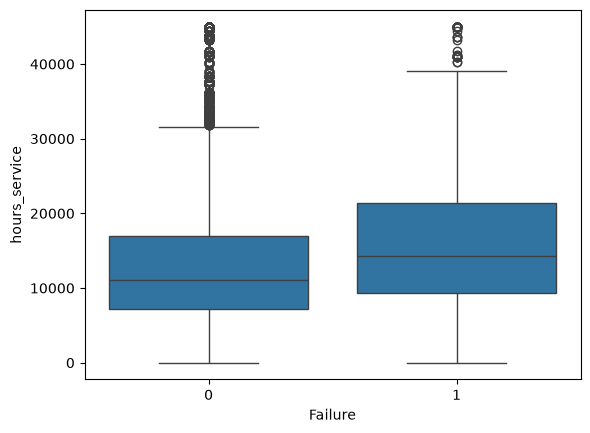

In [43]:
g0 = data.loc[data['Failure'] == 0, 'hours_service'].dropna()
g1 = data.loc[data['Failure'] == 1, 'hours_service'].dropna()

# 1. Boxplot
sns.boxplot(x='Failure', y='hours_service', data=data)

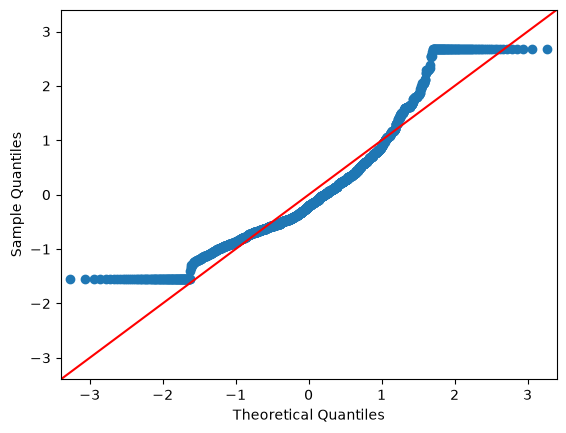

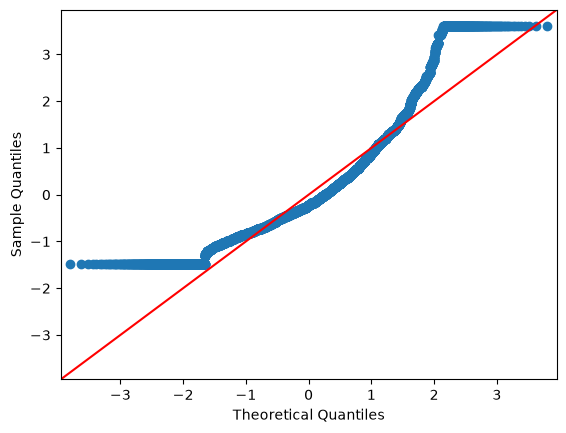

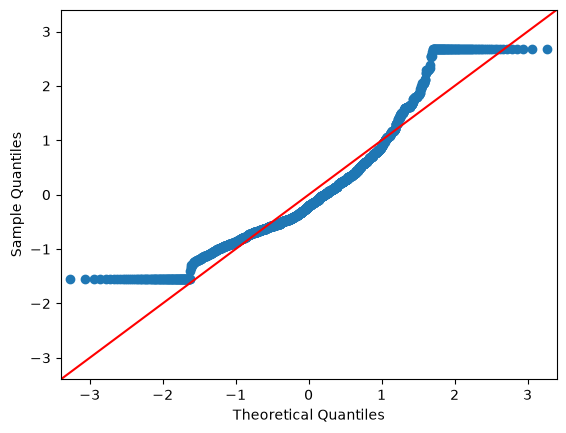

In [44]:
# 2. QQ-plot
sm.ProbPlot(g0, fit=True).qqplot(line='45')
sm.ProbPlot(g1, fit=True).qqplot(line='45')

In [45]:
# 3. Shapiro-Wilk (на вибірці, бо при великому N тест стає надто чутливим)
print(stats.shapiro(g0.sample(5000, random_state=0)))
print(stats.shapiro(g1.sample(min(len(g1), 5000), random_state=0)))

# 4. Levene
print(stats.levene(g0, g1))

ShapiroResult(statistic=np.float64(0.9041440400693359), pvalue=np.float64(1.6817377802744615e-48))
ShapiroResult(statistic=np.float64(0.9213772276558536), pvalue=np.float64(5.738336145484253e-30))
LeveneResult(statistic=np.float64(97.25150886977032), pvalue=np.float64(7.118700060115288e-23))


Both groups are strongly non-normal (Shapiro-Wilk p-values far below 0.001), and their variances differ (Levene p-value far below 0.001). A t-test is therefore not appropriate, and the rank-based **Mann-Whitney U test** is used.

### 6.2 Mann-Whitney U test

In [46]:
u_stat, p_value = mannwhitneyu(g1, g0, alternative="greater")
n1, n0 = len(g1), len(g0)
auc = u_stat / (n1 * n0)  # probability that a random failure record has a higher value

print(f"U = {u_stat:,.0f}, p = {p_value:.2e}")
print(f"AUC = {auc:.3f}")
print("Medians:", g0.median(), "(no failure) vs", g1.median(), "(failure)")

U = 15,240,425, p = 1.07e-43
AUC = 0.599
Medians: 11140.0 (no failure) vs 14280.9 (failure)


**Result:** p ≈ 1e-43, so H0 is rejected at α = 0.05. Failure rows tend to have higher `hours_service`.

AUC is the probability that a randomly chosen failure row has a higher `hours_service` than a randomly chosen non-failure row. AUC = 0.5 means no difference. A value of about 0.6 is a modest effect.

The p-value is likely overstated, because rows from the same machine are correlated. Section 6.3 checks this.

### 6.3 Robustness: without filled zeros

Missing `hours_service` values were filled with 0. To check that this does not drive the result, the test is repeated on rows with `hours_service > 0`. This also removes any genuine zeros.

In [47]:
# (a) Exclude the filled zeros
mask = data["service_missing"] == 0
u_nz, p_nz = mannwhitneyu(
    data.loc[mask & (data["Failure"] == 1), "hours_service"],
    data.loc[mask & (data["Failure"] == 0), "hours_service"],
    alternative="greater",
)
print(f"Without filled zeros: p = {p_nz:.2e}")

# (b) Unit-level analysis: one observation per machine
unit_level = data.groupby("unitId").agg(
    hours=("hours_service", "first"),
    fail_rate=("Failure", "mean"),
)
rho, p_rho = spearmanr(unit_level["hours"], unit_level["fail_rate"])
print(f"Unit-level Spearman rho = {rho:.3f}, p = {p_rho:.2e}")

Without filled zeros: p = 3.06e-52
Unit-level Spearman rho = 0.229, p = 3.32e-25


**Result:** 
 - the effect remains after excluding the filled zeros (p ≈ 3e-52). 
 - ρ = 0.229 (p < 0.0001). Machines with more service hours tend to have a higher failure rate. The correlation is weak, so `hours_service` alone is not a strong predictor.

### 6.5 Statistical power

Power is the probability of detecting a real effect of a given size, if it exists. Here I compute:

- Cohen's d (standardised difference of means), which is only an approximation because the data are not normal.
- The power at the observed number of rows. This is inflated, because rows are not independent.
- The number of machines per group needed for power 0.8 at the unit level. This is the more honest number.

In [48]:
# Effect size on rows: Cohen's d (failure vs non-failure rows)
pooled_sd = np.sqrt((g0.var() + g1.var()) / 2)
d_rows = (g1.mean() - g0.mean()) / pooled_sd
print(f"Cohen's d (rows) = {d_rows:.3f}")

# Power at the observed number of rows
power_rows = TTestIndPower().power(
    effect_size=abs(d_rows), nobs1=len(g1), ratio=len(g0) / len(g1), alpha=0.05
)
print(f"Power (rows, n1={len(g1)}, n0={len(g0)}) = {power_rows:.3f}")

Cohen's d (rows) = 0.338
Power (rows, n1=1842, n0=13815) = 1.000


In [49]:
# One row per machine: hours_service and share of failure rows (used in 6.3 and 6.5)
unit = data.groupby('unitId').agg(
    hours=('hours_service', 'first'),
    fail_rate=('Failure', 'mean')
)


In [50]:
# Unit level: one observation per machine
unit_g0 = unit.loc[unit["fail_rate"] == 0, "hours"]
unit_g1 = unit.loc[unit["fail_rate"] > 0, "hours"]
d_units = (unit_g1.mean() - unit_g0.mean()) / np.sqrt((unit_g0.var() + unit_g1.var()) / 2)

# Machines per group needed for power 0.8 at alpha 0.05
n_needed = TTestIndPower().solve_power(effect_size=abs(d_units), power=0.8, alpha=0.05, ratio=1)
print(f"Cohen's d (units) = {d_units:.3f}")
print(f"Machines per group needed for power 0.8 ≈ {n_needed:.0f} "
      f"(available: {len(unit_g0)} without failures, {len(unit_g1)} with failures)")

Cohen's d (units) = 0.335
Machines per group needed for power 0.8 ≈ 141 (available: 886 without failures, 1114 with failures)


**How to read this:** the row-level power is high, but it overstates the evidence because rows from the same machine are correlated. The unit-level number shows how many machines per group would be needed for a reliable test of this effect. Compare it with the available machine counts printed above.

The power calculation uses a t-test formula on a non-normal variable, so treat the numbers as approximate.

## 7. Summary of the data preparation

| Step | Result |
|---|---|
| Raw readings | 16,038 rows |
| Duplicate rows removed (readings) | 237 |
| Rows without matching machine or gateway (orphans) removed | 144 (125 unique unit IDs) |
| Final rows used | 15,657 |
| `hours_service` missing | filled with 0 (indicator kept until section 1.8) |
| `dpFilter`, `rmsVibration`, `humidityIntake` missing | linear interpolation per machine |
| `temperature_oil` = -999 | set to NaN, then interpolated per machine |
| `current_aux` = 0 | set to NaN, then interpolated per machine |
| `depotId` = 0 | kept (19 machines, consistent per machine) |
| Outliers | flagged with IQR, not removed; clipping shown as an alternative |